# CSC 4110 – Machine Learning

## Group G9 – Staff Attrition

### Task 4: Classification

**Owner:** Obed Kiprono

**Registration Number:** COM/0036/23

1. Dataset Loading and Target Preparation
2. Logistic Regression
3. K-Nearest Neighbours (KNN)
4. Gaussian Naive Bayes
5. Support Vector Machine (SVM)
6. Model Evaluation and Comparison
7. ROC Curve and AUC Analysis
8. Written Interpretation and Conclusion

**Module:** 5

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/CSC4110_G09")

matches = list(PROJECT_DIR.rglob("clean_hr.csv"))

print("Dataset search results:")

for file in matches:
    print(file)

Dataset search results:
/content/drive/MyDrive/CSC4110_G09/data/clean_hr.csv


In [3]:
# Import required libraries
import pandas as pd
import numpy as np
from pathlib import Path

# Define project directory
PROJECT_DIR = Path("/content/drive/MyDrive/CSC4110_G09")
DATA_DIR = PROJECT_DIR / "data"

# Load the cleaned dataset
df = pd.read_csv(DATA_DIR / "clean_hr.csv")

# Separate features and target variable
X = df.drop(columns=["Attrition"])

# Encode the target variable if it is still categorical
if df["Attrition"].dtype == "object":
    y = df["Attrition"].map({"No": 0, "Yes": 1})
else:
    y = df["Attrition"].astype(int)

# Display dataset information
print("Dataset loaded successfully!")
print("-" * 40)
print("Dataset shape:", df.shape)
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Display target distribution
print("\nAttrition Class Distribution:")
print(y.value_counts().sort_index().rename(index={0: "No (Stayed)", 1: "Yes (Left)"}))

# Display class percentages
print("\nAttrition Class Percentages:")
print(
    (y.value_counts(normalize=True) * 100)
    .sort_index()
    .rename(index={0: "No (Stayed)", 1: "Yes (Left)"})
    .round(2)
)

Dataset loaded successfully!
----------------------------------------
Dataset shape: (1470, 51)
Features shape: (1470, 50)
Target shape: (1470,)

Attrition Class Distribution:
Attrition
No (Stayed)    1233
Yes (Left)      237
Name: count, dtype: int64

Attrition Class Percentages:
Attrition
No (Stayed)    83.88
Yes (Left)     16.12
Name: proportion, dtype: float64


Train-Test Split

The dataset is divided into training and testing subsets to evaluate the performance of classification models on unseen data. An 80:20 split is applied, where 80% of the data is used for model training and 20% is reserved for testing.

Stratified sampling is used to preserve the original distribution of the Attrition classes in both subsets. The `random_state=42` parameter ensures reproducibility, allowing the same data split to be obtained whenever the code is executed.

The training set is used to develop the classification models, while the testing set is used to evaluate their ability to correctly identify employees who leave or remain in the organization.

In [4]:
# Import the train-test splitting function
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the resulting dataset sizes
print("Training and Testing Split")
print("-" * 35)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# Check class distribution in the training set
print("\nTraining set class distribution:")
print(y_train.value_counts().sort_index().rename(index={0: "No (Stayed)", 1: "Yes (Left)"}))

print("\nTraining set class percentages:")
print(
    (y_train.value_counts(normalize=True) * 100)
    .sort_index()
    .rename(index={0: "No (Stayed)", 1: "Yes (Left)"})
    .round(2)
)

# Check class distribution in the testing set
print("\nTesting set class distribution:")
print(y_test.value_counts().sort_index().rename(index={0: "No (Stayed)", 1: "Yes (Left)"}))

print("\nTesting set class percentages:")
print(
    (y_test.value_counts(normalize=True) * 100)
    .sort_index()
    .rename(index={0: "No (Stayed)", 1: "Yes (Left)"})
    .round(2)
)

Training and Testing Split
-----------------------------------
X_train shape: (1176, 50)
X_test shape: (294, 50)
y_train shape: (1176,)
y_test shape: (294,)

Training set class distribution:
Attrition
No (Stayed)    986
Yes (Left)     190
Name: count, dtype: int64

Training set class percentages:
Attrition
No (Stayed)    83.84
Yes (Left)     16.16
Name: proportion, dtype: float64

Testing set class distribution:
Attrition
No (Stayed)    247
Yes (Left)      47
Name: count, dtype: int64

Testing set class percentages:
Attrition
No (Stayed)    84.01
Yes (Left)     15.99
Name: proportion, dtype: float64


 Logistic Regression

Logistic Regression is a supervised machine learning classification algorithm used to predict categorical outcomes. In this task, it is applied to predict employee attrition by determining whether an employee is likely to leave the organization or remain employed.

The model estimates the probability of employee attrition based on the available employee features. It uses the logistic (sigmoid) function to transform its predictions into probabilities between 0 and 1. A probability threshold of 0.5 is used to classify employees into the two categories.

The model is evaluated using accuracy, precision, recall, F1-score and a confusion matrix. Since the dataset is imbalanced, particular attention is given to recall for the attrition class, as failing to identify employees who leave may limit the usefulness of the model for employee retention planning.

LOGISTIC REGRESSION EVALUATION
Accuracy : 0.8639
Precision: 0.6400
Recall   : 0.3404
F1-score : 0.4444

Classification Report:
              precision    recall  f1-score   support

 Stayed (No)       0.88      0.96      0.92       247
  Left (Yes)       0.64      0.34      0.44        47

    accuracy                           0.86       294
   macro avg       0.76      0.65      0.68       294
weighted avg       0.85      0.86      0.85       294


Confusion Matrix:
[[238   9]
 [ 31  16]]


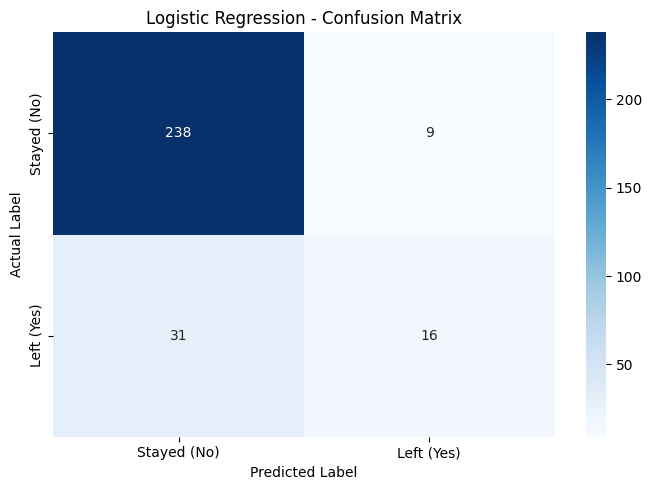


Confusion matrix saved to: /content/drive/MyDrive/CSC4110_G09/outputs/confusion_matrix.png


In [5]:
# Import required libraries
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Identify numerical and categorical features
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Build Logistic Regression pipeline
log_reg = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

# Train the model
log_reg.fit(X_train, y_train)

# Generate predictions
y_pred = log_reg.predict(X_test)

# Generate predicted probabilities for the attrition class
y_prob = log_reg.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display metrics
print("LOGISTIC REGRESSION EVALUATION")
print("=" * 45)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed (No)", "Left (Yes)"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(cm)

# Create output directory
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Plot and save confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed (No)", "Left (Yes)"],
    yticklabels=["Stayed (No)", "Left (Yes)"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

# Save confusion matrix
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nConfusion matrix saved to:", OUTPUT_DIR / "confusion_matrix.png")

In [6]:
print("Logistic Regression Metrics")
print("=" * 40)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall  : {recall:.4f}")
print(f"F1-score: {f1:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed (No)", "Left (Yes)"],
    zero_division=0
))

Logistic Regression Metrics
Accuracy : 0.8639
Precision: 0.6400
Recall  : 0.3404
F1-score: 0.4444

Confusion Matrix:
[[238   9]
 [ 31  16]]

Classification Report:
              precision    recall  f1-score   support

 Stayed (No)       0.88      0.96      0.92       247
  Left (Yes)       0.64      0.34      0.44        47

    accuracy                           0.86       294
   macro avg       0.76      0.65      0.68       294
weighted avg       0.85      0.86      0.85       294



### Interpretation of Logistic Regression Results

The Logistic Regression model achieved an accuracy of 86.39%, indicating that it correctly classified most employees in the test set. However, its recall for employees who left the organization was 34.04%, meaning that it identified only 16 out of the 47 actual employees who left. The model failed to identify 31 employees who left, class

## 4. K-Nearest Neighbours (KNN)

K-Nearest Neighbours (KNN) is a supervised machine learning classification algorithm that classifies observations based on the classes of their nearest data points. It calculates the distance between a new observation and training observations, identifies the nearest neighbours, and assigns the class with the majority vote.

In this task, KNN is used to predict employee attrition by testing different values of K (3, 5, and 7). Feature scaling is applied because KNN relies on distance calculations, and features with larger numerical ranges could otherwise dominate the classification process.

The models are evaluated using accuracy, precision, recall, and F1-score to compare their performance in predicting employees who leave or remain in the organization.

In [7]:
# Import KNN classifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Test different K values
k_values = [3, 5, 7]

knn_results = []

for k in k_values:
    # Create KNN pipeline
    knn_model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])

    # Train model
    knn_model.fit(X_train, y_train)

    # Predict test data
    knn_pred = knn_model.predict(X_test)

    # Calculate evaluation metrics
    knn_accuracy = accuracy_score(y_test, knn_pred)
    knn_precision = precision_score(y_test, knn_pred, zero_division=0)
    knn_recall = recall_score(y_test, knn_pred, zero_division=0)
    knn_f1 = f1_score(y_test, knn_pred, zero_division=0)

    # Store results
    knn_results.append({
        "Model": f"KNN (k={k})",
        "K": k,
        "Accuracy": knn_accuracy,
        "Precision": knn_precision,
        "Recall": knn_recall,
        "F1-Score": knn_f1
    })

# Convert results to DataFrame
knn_results_df = pd.DataFrame(knn_results)

# Display results
print("K-Nearest Neighbours (KNN) Results")
display(knn_results_df.round(4))

K-Nearest Neighbours (KNN) Results


,Model,K,Accuracy,Precision,Recall,F1-Score
0,KNN (k=3),3,0.8061,0.2222,0.0851,0.1231
1,KNN (k=5),5,0.8401,0.5000,0.1064,0.1754
2,KNN (k=7),7,0.8469,0.6667,0.0851,0.1509


### Interpretation of KNN Results

The K-Nearest Neighbours models were evaluated using K values of 3, 5 and 7. KNN (k=7) achieved the highest accuracy of 84.69% and precision of 66.67%, while KNN (k=5) achieved the highest recall of 10.64% and F1-score of 17.54%. Increasing K improved accuracy but did not consistently improve the identification of employees who left the organization.

All three KNN models demonstrated low recall, indicating that they failed to identify most employees who actually left. Although KNN (k=7) performed best in terms of overall accuracy, KNN (k=5) was relatively better in balancing precision and recall for the attrition class. These results demonstrate that accuracy alone is insufficient for evaluating models on an imbalanced dataset.

## 5. Gaussian Naive Bayes

Gaussian Naive Bayes is a supervised classification algorithm based on Bayes' theorem. It estimates the probability of an observation belonging to a particular class using the values of its features. The algorithm assumes that numerical features follow a Gaussian distribution within each class and that the features are conditionally independent.

In this task, Gaussian Naive Bayes is used to predict employee attrition. The model learns the probability of an employee leaving or remaining in the organization from the training data and assigns the class with the highest estimated probability. Its performance is evaluated using accuracy, precision, recall and F1-score.

In [8]:
# Import Gaussian Naive Bayes
from sklearn.naive_bayes import GaussianNB

# Create a dense preprocessing pipeline for GaussianNB
gnb_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
         categorical_features)
    ]
)

# Build Gaussian Naive Bayes pipeline
gnb_model = Pipeline([
    ("preprocessor", gnb_preprocessor),
    ("classifier", GaussianNB())
])

# Train the model
gnb_model.fit(X_train, y_train)

# Generate predictions
gnb_pred = gnb_model.predict(X_test)

# Evaluate the model
gnb_accuracy = accuracy_score(y_test, gnb_pred)
gnb_precision = precision_score(y_test, gnb_pred, zero_division=0)
gnb_recall = recall_score(y_test, gnb_pred, zero_division=0)
gnb_f1 = f1_score(y_test, gnb_pred, zero_division=0)

# Display results
print("GAUSSIAN NAIVE BAYES RESULTS")
print("=" * 40)
print(f"Accuracy : {gnb_accuracy:.4f}")
print(f"Precision: {gnb_precision:.4f}")
print(f"Recall   : {gnb_recall:.4f}")
print(f"F1-score : {gnb_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    gnb_pred,
    target_names=["Stayed (No)", "Left (Yes)"],
    zero_division=0
))

GAUSSIAN NAIVE BAYES RESULTS
Accuracy : 0.6293
Precision: 0.2540
Recall   : 0.6809
F1-score : 0.3699

Classification Report:
              precision    recall  f1-score   support

 Stayed (No)       0.91      0.62      0.74       247
  Left (Yes)       0.25      0.68      0.37        47

    accuracy                           0.63       294
   macro avg       0.58      0.65      0.55       294
weighted avg       0.81      0.63      0.68       294



### Interpretation of Gaussian Naive Bayes Results

The Gaussian Naive Bayes classifier achieved an accuracy of 62.93%, precision of 25.40%, recall of 68.09%, and an F1-score of 36.99% for the attrition class. Although the model had lower overall accuracy than the Logistic Regression and KNN classifiers, it demonstrated better recall in identifying employees who actually left the organization.

The model successfully detected approximately 68% of actual attrition cases, making it more effective at identifying employees who left. However, its low precision indicates that many employees predicted to leave actually remained in the organization. These results demonstrate a trade-off between identifying more attrition cases and generating false-positive predictions. Therefore, Gaussian Naive Bayes may be useful when identifying potential attrition cases is prioritized, although its predictions require careful interpretation.

**Support Vector Machine (SVM)**

In [9]:
# Import Support Vector Machine
from sklearn.svm import SVC

# Create SVM pipeline
svm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ))
])

# Train SVM
svm_model.fit(X_train, y_train)

# Generate predictions
svm_pred = svm_model.predict(X_test)

# Generate probability predictions for Attrition = Yes
svm_prob = svm_model.predict_proba(X_test)[:, 1]

# Evaluate model
svm_accuracy = accuracy_score(y_test, svm_pred)
svm_precision = precision_score(y_test, svm_pred, zero_division=0)
svm_recall = recall_score(y_test, svm_pred, zero_division=0)
svm_f1 = f1_score(y_test, svm_pred, zero_division=0)

# Display results
print("SUPPORT VECTOR MACHINE (SVM) RESULTS")
print("=" * 45)
print(f"Accuracy : {svm_accuracy:.4f}")
print(f"Precision: {svm_precision:.4f}")
print(f"Recall   : {svm_recall:.4f}")
print(f"F1-score : {svm_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    svm_pred,
    target_names=["Stayed (No)", "Left (Yes)"],
    zero_division=0
))

SUPPORT VECTOR MACHINE (SVM) RESULTS
Accuracy : 0.8639
Precision: 0.7692
Recall   : 0.2128
F1-score : 0.3333

Classification Report:
              precision    recall  f1-score   support

 Stayed (No)       0.87      0.99      0.92       247
  Left (Yes)       0.77      0.21      0.33        47

    accuracy                           0.86       294
   macro avg       0.82      0.60      0.63       294
weighted avg       0.85      0.86      0.83       294



### Interpretation of Support Vector Machine Results

The Support Vector Machine classifier achieved an accuracy of 86.39%, precision of 76.92%, recall of 21.28%, and an F1-score of 33.33% for the attrition class. The model demonstrated relatively high precision, indicating that most employees predicted to leave were correctly classified. However, its low recall shows that it identified only a small proportion of employees who actually left the organization.

Although the SVM model achieved accuracy comparable to Logistic Regression, it performed poorly in identifying the minority attrition class. These results indicate that the model is more effective at making reliable positive predictions than at detecting all employees at risk of leaving. Therefore, its usefulness for employee retention planning is limited when identifying as many potential attrition cases as possible is the main objective.

In [10]:
# Collect classification model evaluation results

results_clf = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    },
    {
        "Model": "KNN (k=3)",
        "Accuracy": knn_results_df.loc[knn_results_df["K"] == 3, "Accuracy"].iloc[0],
        "Precision": knn_results_df.loc[knn_results_df["K"] == 3, "Precision"].iloc[0],
        "Recall": knn_results_df.loc[knn_results_df["K"] == 3, "Recall"].iloc[0],
        "F1-Score": knn_results_df.loc[knn_results_df["K"] == 3, "F1-Score"].iloc[0]
    },
    {
        "Model": "KNN (k=5)",
        "Accuracy": knn_results_df.loc[knn_results_df["K"] == 5, "Accuracy"].iloc[0],
        "Precision": knn_results_df.loc[knn_results_df["K"] == 5, "Precision"].iloc[0],
        "Recall": knn_results_df.loc[knn_results_df["K"] == 5, "Recall"].iloc[0],
        "F1-Score": knn_results_df.loc[knn_results_df["K"] == 5, "F1-Score"].iloc[0]
    },
    {
        "Model": "KNN (k=7)",
        "Accuracy": knn_results_df.loc[knn_results_df["K"] == 7, "Accuracy"].iloc[0],
        "Precision": knn_results_df.loc[knn_results_df["K"] == 7, "Precision"].iloc[0],
        "Recall": knn_results_df.loc[knn_results_df["K"] == 7, "Recall"].iloc[0],
        "F1-Score": knn_results_df.loc[knn_results_df["K"] == 7, "F1-Score"].iloc[0]
    },
    {
        "Model": "Gaussian Naive Bayes",
        "Accuracy": gnb_accuracy,
        "Precision": gnb_precision,
        "Recall": gnb_recall,
        "F1-Score": gnb_f1
    },
    {
        "Model": "Support Vector Machine",
        "Accuracy": svm_accuracy,
        "Precision": svm_precision,
        "Recall": svm_recall,
        "F1-Score": svm_f1
    }
])

# Sort models by F1-score
results_clf = results_clf.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

# Display results
print("CLASSIFICATION MODEL COMPARISON")
print("=" * 70)

display(results_clf.round(4))

CLASSIFICATION MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8639,0.6400,0.3404,0.4444
1,Gaussian Naive Bayes,0.6293,0.2540,0.6809,0.3699
2,Support Vector Machine,0.8639,0.7692,0.2128,0.3333
3,KNN (k=5),0.8401,0.5000,0.1064,0.1754
4,KNN (k=7),0.8469,0.6667,0.0851,0.1509
5,KNN (k=3),0.8061,0.2222,0.0851,0.1231


**ROC Curve and AUC Analysis**

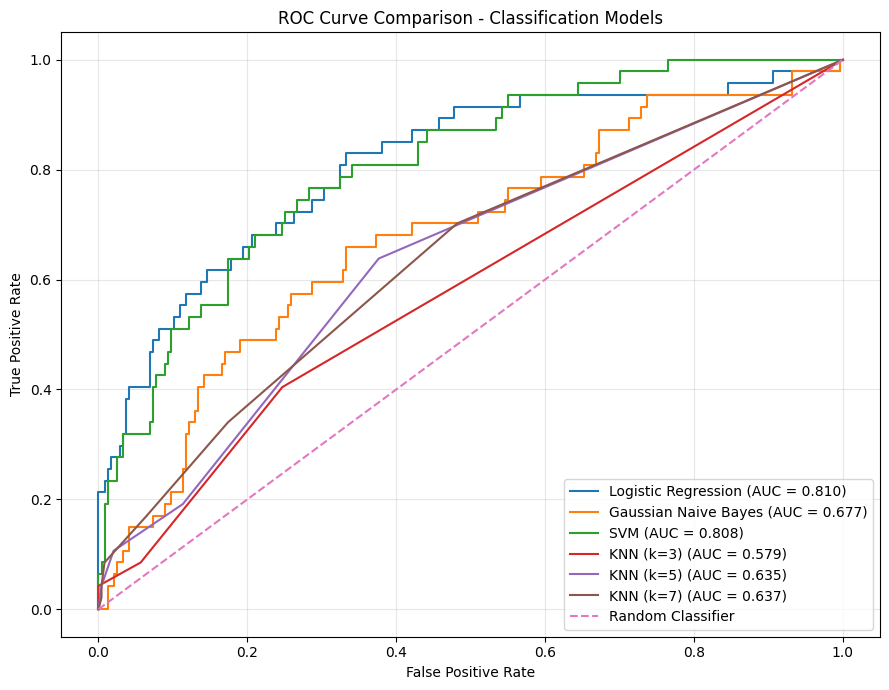

ROC-AUC MODEL COMPARISON


,Model,AUC
0,Logistic Regression,0.8101
1,SVM,0.8076
2,Gaussian Naive Bayes,0.6771
3,KNN (k=7),0.6369
4,KNN (k=5),0.6351
5,KNN (k=3),0.5789



ROC plot saved to: /content/drive/MyDrive/CSC4110_G09/outputs/classification_roc_curves.png


In [11]:
# Import ROC and AUC functions
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt

# Prepare classification models for ROC analysis
roc_models = {
    "Logistic Regression": log_reg,
    "Gaussian Naive Bayes": gnb_model,
    "SVM": svm_model
}

# Re-train KNN models and include them in ROC analysis
for k in [3, 5, 7]:
    roc_models[f"KNN (k={k})"] = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])

# Create ROC plot
plt.figure(figsize=(9, 7))

auc_results = []

for model_name, model in roc_models.items():

    # Train the model
    model.fit(X_train, y_train)

    # Obtain probability estimates for the positive class
    probabilities = model.predict_proba(X_test)[:, 1]

    # Calculate ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, probabilities)

    # Calculate AUC
    auc_score = roc_auc_score(y_test, probabilities)

    auc_results.append({
        "Model": model_name,
        "AUC": auc_score
    })

    # Plot ROC curve
    plt.plot(fpr, tpr, label=f"{model_name} (AUC = {auc_score:.3f})")

# Plot random classifier reference line
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

# Configure plot
plt.title("ROC Curve Comparison - Classification Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

# Save ROC plot
roc_path = OUTPUT_DIR / "classification_roc_curves.png"
plt.savefig(roc_path, dpi=300, bbox_inches="tight")
plt.show()

# Display AUC results
auc_results_df = pd.DataFrame(auc_results).sort_values(
    by="AUC",
    ascending=False
).reset_index(drop=True)

print("ROC-AUC MODEL COMPARISON")
print("=" * 45)
display(auc_results_df.round(4))

print("\nROC plot saved to:", roc_path)

In [12]:
# Ensure the ROC curve is available under the required filename
roc_source = OUTPUT_DIR / "classification_roc_curves.png"
roc_target = OUTPUT_DIR / "roc_curve.png"

if roc_source.exists():
    import shutil
    shutil.copy(roc_source, roc_target)
    print("ROC curve copied successfully to:", roc_target)
else:
    print("Original ROC plot was not found.")

ROC curve copied successfully to: /content/drive/MyDrive/CSC4110_G09/outputs/roc_curve.png


In [13]:
# Logistic Regression with balanced class weights

log_reg_balanced = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the balanced model
log_reg_balanced.fit(X_train, y_train)

# Predict on the test set
y_pred_balanced = log_reg_balanced.predict(X_test)

# Calculate evaluation metrics
accuracy_balanced = accuracy_score(y_test, y_pred_balanced)
precision_balanced = precision_score(y_test, y_pred_balanced, zero_division=0)
recall_balanced = recall_score(y_test, y_pred_balanced, zero_division=0)
f1_balanced = f1_score(y_test, y_pred_balanced, zero_division=0)

# Display results
print("LOGISTIC REGRESSION - BALANCED CLASS WEIGHTS")
print("=" * 50)
print(f"Accuracy : {accuracy_balanced:.4f}")
print(f"Precision: {precision_balanced:.4f}")
print(f"Recall   : {recall_balanced:.4f}")
print(f"F1-score: {f1_balanced:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_balanced,
    target_names=["Stayed (No)", "Left (Yes)"],
    zero_division=0
))

LOGISTIC REGRESSION - BALANCED CLASS WEIGHTS
Accuracy : 0.7653
Precision: 0.3659
Recall   : 0.6383
F1-score: 0.4651

Classification Report:
              precision    recall  f1-score   support

 Stayed (No)       0.92      0.79      0.85       247
  Left (Yes)       0.37      0.64      0.47        47

    accuracy                           0.77       294
   macro avg       0.64      0.71      0.66       294
weighted avg       0.83      0.77      0.79       294



In [14]:
# Compare Original and Balanced Logistic Regression

logistic_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression (Original)",
        "Logistic Regression (Balanced)"
    ],
    "Accuracy": [accuracy, accuracy_balanced],
    "Precision": [precision, precision_balanced],
    "Recall": [recall, recall_balanced],
    "F1-score": [f1, f1_balanced]
})

display(logistic_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression (Original),0.8639,0.6400,0.3404,0.4444
1,Logistic Regression (Balanced),0.7653,0.3659,0.6383,0.4651


The comparison between the original and balanced Logistic Regression models shows the effect of applying class weighting to an imbalanced dataset. The original model achieved a higher accuracy of 86.39% and precision of 64.00%, but a relatively low recall of 34.04%, indicating that it failed to identify many employees who actually left the organization.

The balanced model reduced accuracy to 76.53% and precision to 36.59%, but increased recall to 63.83% and the F1-score from 44.44% to 46.51%. This indicates that class weighting improved the model's ability to detect employees who left, although it also increased false-positive predictions.

Overall, the balanced Logistic Regression model is more effective at identifying employee attrition cases, while the original model is better at maintaining higher accuracy and precision. The choice between the two depends on whether the priority is detecting more employees at risk of leaving or minimizing false alarms.